In [ ]:
# 05 — Evaluación e interpretación del modelo

## 1. Objetivo

En este notebook se profundiza en la evaluación de los modelos desarrollados
para la predicción del riesgo de crédito.

El análisis se centrará principalmente en Random Forest, que presentó mejores
métricas que la regresión logística en la comparación anterior.

Los objetivos son:

- Reproducir el proceso de entrenamiento.
- Comparar de forma resumida ambos modelos.
- Analizar la matriz de confusión del Random Forest.
- Estudiar la importancia de las variables.
- Interpretar los resultados desde una perspectiva de riesgo de crédito.
- Extraer las conclusiones finales del modelado.

In [ ]:
## 2. Importación de librerías y carga de datos

Se importan las librerías necesarias y se carga nuevamente el dataset original
para mantener el notebook reproducible e independiente de los notebooks
anteriores.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

In [2]:
df = pd.read_csv(r"C:\Users\Sistemas\Desktop\BOOTCAMP DATA\Master Data Sciencie & AI\Proyecto banking\hmeq.csv")


print("Dimensiones:", df.shape)

df.head()

Dimensiones: (5960, 13)


,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
0,1,1100,25860.0,39025.0,HomeImp,Other,10.5,0.0,0.0,94.366667,1.0,9.0,NaN
1,1,1300,70053.0,68400.0,HomeImp,Other,7.0,0.0,2.0,121.833333,0.0,14.0,NaN
2,1,1500,13500.0,16700.0,HomeImp,Other,4.0,0.0,0.0,149.466667,1.0,10.0,NaN
3,1,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1700,97800.0,112000.0,HomeImp,Office,3.0,0.0,0.0,93.333333,0.0,14.0,NaN


In [ ]:
## 3. Preparación de los datos

Se utiliza la misma división train/test empleada durante el modelado,
manteniendo el 80 % de las observaciones para entrenamiento y el 20 %
para prueba.

La estratificación permite conservar aproximadamente la proporción original
de las clases `BAD = 0` y `BAD = 1`.

In [3]:
X = df.drop(columns="BAD")
y = df["BAD"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (4768, 12)
Test : (1192, 12)


In [ ]:
## 4. Reconstrucción del preprocesamiento

Se reproduce el mismo pipeline de preprocesamiento utilizado durante el
modelado para garantizar la consistencia de los resultados.

In [4]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns

In [5]:
numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value="Missing"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [ ]:
## 5. Reconstrucción de los modelos

Se vuelven a entrenar la regresión logística y Random Forest utilizando
el mismo preprocesamiento y los mismos datos empleados en el notebook
anterior.

In [8]:
log_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000
            )
        )
    ]
)

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42
            )
        )
    ]
)

In [10]:
log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [11]:
log_pred = log_model.predict(X_test)
log_prob = log_model.predict_proba(X_test)[:, 1]

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

In [ ]:
## 6. Comparación de los modelos

Se comparan ambos modelos mediante distintas métricas para obtener una visión
más completa de su comportamiento predictivo.

In [12]:
resultados = pd.DataFrame({
    "Modelo": [
        "Regresión Logística",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, log_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, log_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, log_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1-score": [
        f1_score(y_test, log_pred),
        f1_score(y_test, rf_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, log_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})

resultados.round(4)

,Modelo,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Regresión Logística,0.8834,0.7676,0.5966,0.6714,0.9004
1,Random Forest,0.9044,0.8196,0.6681,0.7361,0.9629


In [ ]:
## 7. Análisis de errores de Random Forest

Dado que Random Forest presentó los mejores resultados en la comparación
realizada, se analiza con mayor detalle su matriz de confusión.

El objetivo es identificar los aciertos y, especialmente, los tipos de error
que pueden resultar relevantes desde una perspectiva de riesgo de crédito.

In [13]:
cm_rf = confusion_matrix(y_test, rf_pred)

cm_rf

array([[919,  35],
       [ 79, 159]])

In [ ]:
### Interpretación

Random Forest clasifica correctamente 919 clientes `BAD = 0` y 159 clientes
`BAD = 1`.

El modelo genera 35 falsos positivos y 79 falsos negativos.

Los falsos negativos son especialmente relevantes desde una perspectiva de
riesgo de crédito, ya que representan clientes que pertenecen a `BAD = 1`
pero que el modelo clasifica como `BAD = 0`.

Aunque Random Forest reduce este tipo de error respecto a la regresión
logística, todavía existen casos de riesgo que el modelo no consigue detectar.

In [ ]:
## 8. Importancia de las variables

Random Forest permite estimar la importancia relativa de las variables
utilizadas durante el entrenamiento.

Este análisis ayuda a comprender qué características tienen mayor peso en
las decisiones del modelo y permite comparar los resultados del Machine
Learning con los patrones identificados previamente durante el EDA y el
análisis estadístico.

In [14]:
feature_names = (
    rf_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

feature_names[:20]

array(['num__LOAN', 'num__MORTDUE', 'num__VALUE', 'num__YOJ',
       'num__DEROG', 'num__DELINQ', 'num__CLAGE', 'num__NINQ',
       'num__CLNO', 'num__DEBTINC', 'num__missingindicator_MORTDUE',
       'num__missingindicator_VALUE', 'num__missingindicator_YOJ',
       'num__missingindicator_DEROG', 'num__missingindicator_DELINQ',
       'num__missingindicator_CLAGE', 'num__missingindicator_NINQ',
       'num__missingindicator_CLNO', 'num__missingindicator_DEBTINC',
       'cat__REASON_DebtCon'], dtype=object)

In [15]:
importances = (
    rf_model
    .named_steps["classifier"]
    .feature_importances_
)

feature_importance = pd.DataFrame({
    "Variable": feature_names,
    "Importancia": importances
})

feature_importance = feature_importance.sort_values(
    "Importancia",
    ascending=False
)

feature_importance.head(15)

,Variable,Importancia
18,num__missingindicator_DEBTINC,0.176138
9,num__DEBTINC,0.141261
6,num__CLAGE,0.086618
5,num__DELINQ,0.080290
2,num__VALUE,0.068730
0,num__LOAN,0.068610
8,num__CLNO,0.063044
1,num__MORTDUE,0.062256
3,num__YOJ,0.050489
4,num__DEROG,0.041289


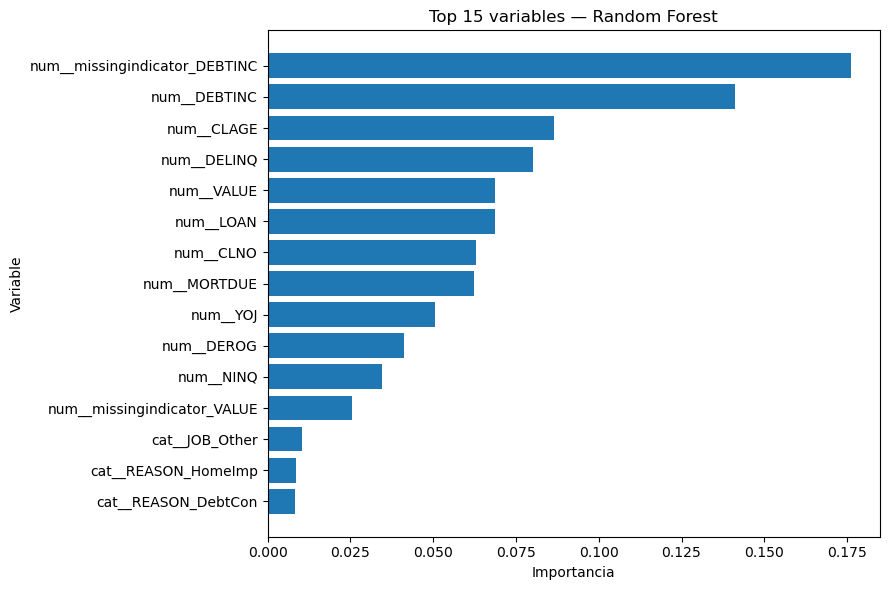

In [16]:
top_features = feature_importance.head(15).sort_values(
    "Importancia"
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Variable"],
    top_features["Importancia"]
)

plt.title("Top 15 variables — Random Forest")
plt.xlabel("Importancia")
plt.ylabel("Variable")

plt.tight_layout()
plt.show()

In [18]:
SimpleImputer(
    strategy="median",
    add_indicator=True
)

,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,True
,keep_empty_features,False


In [ ]:
### Interpretación de la importancia de variables

La característica con mayor importancia en Random Forest es el indicador de
ausencia de `DEBTINC`, seguida por la propia variable `DEBTINC`.

Este resultado es coherente con el análisis inicial de valores ausentes, donde
se observó una asociación especialmente marcada entre la ausencia de `DEBTINC`
y la variable objetivo. Por tanto, conservar información sobre los valores
ausentes mediante indicadores resultó relevante para el modelo.

También presentan una importancia destacada `CLAGE` y `DELINQ`, variables que
ya habían mostrado diferencias entre los grupos `BAD = 0` y `BAD = 1` durante
el análisis exploratorio y estadístico.

Otras variables como `VALUE`, `LOAN`, `CLNO`, `MORTDUE`, `YOJ`, `DEROG` y
`NINQ` también contribuyen a las predicciones, aunque con menor importancia
individual.

Las variables categóricas transformadas mediante One-Hot Encoding presentan,
en general, una importancia menor que las principales variables numéricas.

Estas importancias deben interpretarse como una medida del uso de las
características dentro del Random Forest y no como evidencia de causalidad.

In [ ]:
NOTEBOOK 01
Missing DEBTINC → asociación muy fuerte con BAD
            ↓
NOTEBOOK 02
DEBTINC / DELINQ / CLAGE → patrones descriptivos
            ↓
NOTEBOOK 03
DEBTINC / DELINQ / CLAGE → diferencias estadísticas
            ↓
NOTEBOOK 04
Random Forest → ROC-AUC 0.9629
            ↓
NOTEBOOK 05
Missing DEBTINC / DEBTINC / CLAGE / DELINQ
→ entre las características más utilizadas por el modelo

In [ ]:
## 9. Conclusiones del modelado

El análisis realizado permite extraer las siguientes conclusiones:

- Random Forest presentó mejores métricas que la regresión logística en el
  conjunto de prueba, alcanzando un accuracy del 90,44 %, un recall del
  66,81 %, un F1-score de 0,7361 y un ROC-AUC de 0,9629.

- El modelo identificó correctamente 159 de los 238 clientes `BAD = 1`,
  aunque todavía clasificó incorrectamente 79 casos de esta clase como
  `BAD = 0`.

- Entre las características con mayor importancia aparecen el indicador de
  ausencia de `DEBTINC`, la propia variable `DEBTINC`, `CLAGE` y `DELINQ`.

- Estos resultados son coherentes con varios de los patrones observados
  previamente durante el análisis exploratorio y estadístico.

- La elevada importancia del indicador de ausencia de `DEBTINC` confirma la
  utilidad predictiva de conservar información sobre los valores ausentes en
  lugar de limitarse a imputarlos.

- Las importancias del Random Forest representan contribución predictiva
  dentro del modelo y no deben interpretarse como relaciones causales.

En conjunto, el proyecto muestra que es posible construir un modelo capaz de
discriminar entre distintos niveles de riesgo utilizando información
financiera y crediticia de los clientes. No obstante, la existencia de falsos
negativos demuestra que las predicciones deben interpretarse como una
herramienta de apoyo al análisis de riesgo y no como una decisión automática.

In [ ]:
## 10. Resumen del proceso analítico

El proyecto ha seguido un flujo completo de análisis de datos y Machine
Learning:

1. **Data Understanding:** análisis de estructura, calidad y valores ausentes.
2. **EDA:** identificación de distribuciones, valores extremos y patrones
   relacionados con `BAD`.
3. **Análisis estadístico:** contraste de las diferencias y asociaciones
   observadas durante el EDA.
4. **Preprocesamiento y modelado:** construcción de pipelines y entrenamiento
   de regresión logística y Random Forest.
5. **Evaluación e interpretación:** análisis de errores, métricas predictivas
   e importancia de variables.

Los resultados obtenidos servirán como base para desarrollar una visualización
ejecutiva en Power BI orientada al análisis de riesgo de crédito.

In [ ]:
credit-risk-project/
│
├── data/
│   └── hmeq.csv
│
├── notebooks/
│   ├── 01_data_understanding.ipynb
│   ├── 02_exploratory_data_analysis.ipynb
│   ├── 03_statistical_analysis.ipynb
│   ├── 04_preprocessing_modeling.ipynb
│   └── 05_model_evaluation.ipynb
│
└── ...

In [ ]:
## 11. Preparación del dataset para Power BI

Para facilitar la visualización y el análisis de los resultados del modelo,
se genera un dataset específico para Power BI.

El archivo incluirá las variables originales de los clientes del conjunto
de prueba junto con:

- El resultado real (`BAD`).
- La predicción realizada por Random Forest.
- La probabilidad estimada de pertenecer a `BAD = 1`.
- El resultado de la clasificación.
- Una categoría de riesgo basada en la probabilidad estimada.

Este dataset permitirá analizar conjuntamente las características de los
clientes y los resultados del modelo.

In [19]:
powerbi_df = X_test.copy()

powerbi_df["BAD_REAL"] = y_test
powerbi_df["BAD_PRED"] = rf_pred
powerbi_df["PROB_BAD"] = rf_prob

In [20]:
powerbi_df.head()

,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC,BAD_REAL,BAD_PRED,PROB_BAD
4798,25100,41314.0,71357.0,DebtCon,Office,19.0,0.0,0.0,183.631428,1.0,22.0,33.665534,0,0,0.005
3716,19600,33284.0,61824.0,DebtCon,Other,14.0,0.0,0.0,119.473073,1.0,17.0,37.784524,0,0,0.035
1472,11000,54641.0,65705.0,DebtCon,Other,5.0,0.0,0.0,323.192928,0.0,10.0,33.299628,0,0,0.005
1050,9600,45240.0,60136.0,DebtCon,Other,2.0,0.0,1.0,83.066751,0.0,19.0,38.454300,0,0,0.130
87,4000,58000.0,69440.0,HomeImp,Other,3.5,0.0,1.0,168.666667,0.0,18.0,NaN,1,1,0.615


In [ ]:
BAD_REAL   → lo que ocurrió realmente
BAD_PRED   → lo que predijo Random Forest
PROB_BAD   → puntuación/probabilidad estimada por el modelo

In [21]:
def clasificar_resultado(row):
    if row["BAD_REAL"] == 0 and row["BAD_PRED"] == 0:
        return "Verdadero Negativo"
    elif row["BAD_REAL"] == 0 and row["BAD_PRED"] == 1:
        return "Falso Positivo"
    elif row["BAD_REAL"] == 1 and row["BAD_PRED"] == 0:
        return "Falso Negativo"
    else:
        return "Verdadero Positivo"

powerbi_df["RESULTADO_MODELO"] = powerbi_df.apply(
    clasificar_resultado,
    axis=1
)

In [22]:
powerbi_df["RESULTADO_MODELO"].value_counts()

RESULTADO_MODELO
Verdadero Negativo    919
Verdadero Positivo    159
Falso Negativo         79
Falso Positivo         35
Name: count, dtype: int64

In [ ]:
## Crear segmentos de riesgo 

In [23]:
powerbi_df["NIVEL_RIESGO"] = pd.cut(
    powerbi_df["PROB_BAD"],
    bins=[0, 0.20, 0.50, 0.80, 1.00],
    labels=[
        "Bajo",
        "Medio",
        "Alto",
        "Muy alto"
    ],
    include_lowest=True
)

In [24]:
powerbi_df["NIVEL_RIESGO"].value_counts()

NIVEL_RIESGO
Bajo        876
Medio       122
Alto        113
Muy alto     81
Name: count, dtype: int64

In [ ]:
## Identificador de cliente 

In [25]:
powerbi_df = powerbi_df.reset_index(drop=True)

powerbi_df.insert(
    0,
    "CLIENT_ID",
    ["C" + str(i).zfill(5) for i in range(1, len(powerbi_df) + 1)]
)

In [26]:
powerbi_df[
    [
        "CLIENT_ID",
        "BAD_REAL",
        "BAD_PRED",
        "PROB_BAD",
        "NIVEL_RIESGO",
        "RESULTADO_MODELO"
    ]
].head(10)

,CLIENT_ID,BAD_REAL,BAD_PRED,PROB_BAD,NIVEL_RIESGO,RESULTADO_MODELO
0,C00001,0,0,0.005,Bajo,Verdadero Negativo
1,C00002,0,0,0.035,Bajo,Verdadero Negativo
2,C00003,0,0,0.005,Bajo,Verdadero Negativo
3,C00004,0,0,0.130,Bajo,Verdadero Negativo
4,C00005,1,1,0.615,Alto,Verdadero Positivo
5,C00006,0,0,0.010,Bajo,Verdadero Negativo
6,C00007,0,0,0.010,Bajo,Verdadero Negativo
7,C00008,0,0,0.010,Bajo,Verdadero Negativo
8,C00009,0,0,0.005,Bajo,Verdadero Negativo
9,C00010,0,0,0.005,Bajo,Verdadero Negativo


In [27]:
print("Filas:", powerbi_df.shape[0])
print("Columnas:", powerbi_df.shape[1])

print("\nValores nulos:")
print(powerbi_df.isnull().sum().sort_values(ascending=False))

Filas: 1192
Columnas: 18

Valores nulos:
DEBTINC             262
DEROG               120
YOJ                 112
DELINQ              108
MORTDUE              97
NINQ                 96
REASON               57
CLAGE                49
JOB                  49
CLNO                 38
VALUE                23
BAD_PRED              0
RESULTADO_MODELO      0
PROB_BAD              0
CLIENT_ID             0
BAD_REAL              0
LOAN                  0
NIVEL_RIESGO          0
dtype: int64


In [ ]:
credit-risk-project/
│
├── data/
│   └── hmeq.csv
│
├── notebooks/
│   ├── 01_data_understanding.ipynb
│   ├── 02_exploratory_data_analysis.ipynb
│   ├── 03_statistical_analysis.ipynb
│   ├── 04_preprocessing_modeling.ipynb
│   └── 05_model_evaluation.ipynb
│
└── outputs/

In [28]:
from pathlib import Path

Path("../outputs").mkdir(exist_ok=True)

In [29]:
powerbi_df.to_csv(
    "../outputs/credit_risk_powerbi.csv",
    index=False
)

In [30]:
Path("../outputs/credit_risk_powerbi.csv").exists()

True